# データサイエンス実践A 第７講：ヒストグラム・箱ひげ図とリストの操作
### 新潟大学 創生学部（2026年度）
**講義日：2026年10月27日（火）**

1. はじめに、前回の `value_counts` と `index` を復習する（前回の振り返り）。
1. 次に、**ヒストグラム**（Q-0）と**箱ひげ図**（R-0）の**完成形と部品表**で、今日の要点をまとめて紹介する。
1. そのあと、この notebook を授業HPに公開する。CES-Alpha の演習「**第７講**」（ヒストグラム4問・箱ひげ図3問・リスト4問。ヒストグラム・箱ひげ図とも最後の1問は発展）を解く。
1. 解き方が分からないときは、部品表の「学ぶところ」の節（Q-1〜Q-7、R-1〜R-7、S-1〜S-3）を読む。それでも分からなければ、手を挙げて**個別に質問**する。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**
- [value_counts と index の復習](#value_counts-と-index-の復習)

**[Q. ヒストグラム](#Q.-ヒストグラム)**（演習「第７講」の hist）
- [Q-0 今日の完成形](#Q-0-今日の完成形)
- [Q-1 ヒストグラムの基本：まず手で数えてみる](#Q-1-ヒストグラムの基本：まず手で数えてみる)
- [Q-2 区切りの数](#Q-2-区切りの数)
- [Q-3 色と枠線](#Q-3-色と枠線)
- [Q-4 区切りの範囲](#Q-4-区切りの範囲)
- [Q-5 平均の補助線](#Q-5-平均の補助線)
- [Q-6 2つのグループを重ねる](#Q-6-2つのグループを重ねる)
- [Q-7 Excel のデータでヒストグラム](#Q-7-Excel-のデータでヒストグラム)

**[R. 箱ひげ図](#R.-箱ひげ図)**（演習「第７講」の box）
- [R-0 今日の完成形](#R-0-今日の完成形)
- [R-1 箱ひげ図の読み方](#R-1-箱ひげ図の読み方)
- [R-2 箱ひげ図の基本](#R-2-箱ひげ図の基本)
- [R-3 項目の名前](#R-3-項目の名前)
- [R-4 箱の幅と塗りつぶし](#R-4-箱の幅と塗りつぶし)
- [R-5 平均を表示する](#R-5-平均を表示する)
- [R-6 補助線を引く](#R-6-補助線を引く)
- [R-7 Excel のデータで箱ひげ図](#R-7-Excel-のデータで箱ひげ図)

**[S. リストの操作](#S.-リストの操作)**（演習「第７講」のリスト）
- [S-1 リストの作成と参照（復習）](#S-1-リストの作成と参照（復習）)
- [S-2 同じものを並べる・個数を数える](#S-2-同じものを並べる・個数を数える)
- [S-3 要素を書き換える](#S-3-要素を書き換える)

**[T. 発展（できる人だけ）](#T.-発展（できる人だけ）)**
- [T-1 ヒストグラムを並べる・横向きにする](#T-1-ヒストグラムを並べる・横向きにする)
- [T-2 箱ごとに色を変える](#T-2-箱ごとに色を変える)
- [T-3 ヒストグラムの1本だけ色を変える](#T-3-ヒストグラムの1本だけ色を変える)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は **Excel ファイルを読み**（`pd.read_excel`）、**棒グラフ**（`plt.bar`）と**円グラフ**（`plt.pie`）を描いた
- 新しい notebook はいつもの場所（ホームフォルダ）に作る。`dsa2026data.xlsx` も同じ場所に置いておく。今日も使う
- 列の取り出しは `df['列名']`、列名の一覧は `list(df.columns)`
- 説明文は**マークダウン**で書く（第３講 F-4）。課題の notebook でも、グラフの説明や考察はマークダウンのセルに書く
- 第１回課題の提出、おつかれさまでした
- 前回の O-7 で使った `value_counts()` と `index` を、下で復習する

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
df.head()

,name,国語,数学,理科,社会,英語
0,伊藤 涼介,94,76,62,81,62
1,上田 美咲,63,57,59,80,74
2,木村 太郎,55,66,82,78,66
3,佐藤 亜美,61,87,80,65,78
4,鈴木 恵美子,56,58,69,97,61


- 表が出れば準備完了。`FileNotFoundError` が出たら、`dsa2026data.xlsx` を notebook と同じ場所に置く（第５講 L-1）
- `exam` シートは、30人の5教科のテストの点数（名前は架空）

## value_counts と index の復習

- 前回の O-7 では、**文字**の列（曜日）を `value_counts()` で**数えて**から、円グラフや棒グラフにした
- `tip_data` シートは、あるレストランの244件の会計の記録

In [2]:
df_tip = pd.read_excel('dsa2026data.xlsx', sheet_name='tip_data')
count = df_tip['day'].value_counts()
count

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

- 左の列（Sat, Sun, …）が **index**（数えた値の名前）、右の列が**件数**。件数の多い順に並ぶ
- `count.index` で名前だけ、`count.values` で件数だけを取り出せる

In [3]:
print(count.index)
print(count.values)

Index(['Sat', 'Sun', 'Thur', 'Fri'], dtype='str', name='day')
[87 76 62 19]


- 名前を横軸、件数を棒の高さにすれば棒グラフになる（`plt.bar(count.index, count)` と書いても同じ）

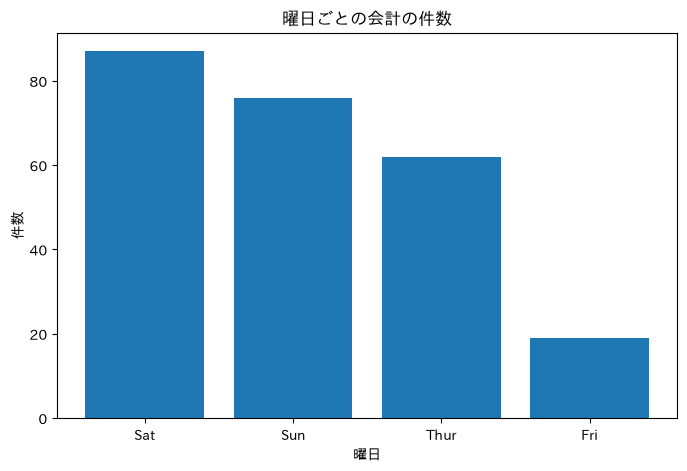

In [4]:
plt.figure(figsize=(8, 5))
plt.bar(count.index, count.values)
plt.title('曜日ごとの会計の件数')
plt.xlabel('曜日')
plt.ylabel('件数')
plt.show()

- **文字**のデータ（曜日）は、同じ値ごとに `value_counts()` で数えた
- **数値**のデータ（点数など）は、同じ値がほとんどないので、そのままでは数えにくい。**区間（0〜10点、10〜20点、…）ごとに数える**のが今日の**ヒストグラム**。数えるのは `plt.hist` がやってくれる

---
# Q. ヒストグラム

**ヒストグラム**は、データを**区間に分けて、それぞれの区間にいくつ入るかを数えた**グラフ。点数が**どのあたりに集まっているか**（分布）を見るときに使う。

| | 棒グラフ | ヒストグラム |
|---|---|---|
| 関数 | `plt.bar(x, y)` | `plt.hist(データ)` |
| 渡すもの | 項目（x）と高さ（y）の**2つ** | データ**1つだけ**（数えるのは matplotlib） |
| 横軸 | 項目（曜日、都市など） | **数値の区間**（0〜10点、10〜20点 …） |
| 縦軸 | 量 | **個数**（人数など） |
| 棒のすき間 | あける | **あけない**（区間がつながっているため） |

演習「第７講」のヒストグラムの問題（hist）のひな形は、Q-1 の最後にある。

## Q-0 今日の完成形

今日はこのグラフを目指す（30人の数学の点数の分布）。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する（`Shift + Enter`）
1. まずは**数値や文字を変えて**、グラフのどこが変わるかを確かめる
1. そのあと1行ずつ分解して、各部品（[0]〜[7]）の働きを学ぶ（Q-1〜Q-6）

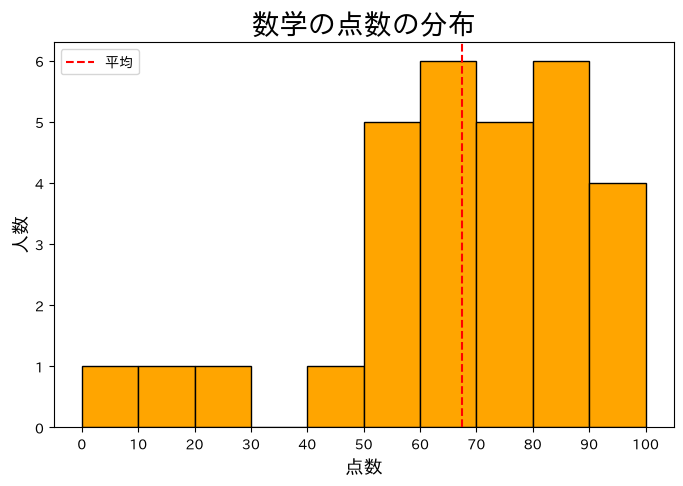

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')  # Excel を読む
data = df['数学']  # 列を取り出す

plt.figure(figsize=(8, 5))  # [0] グラフの大きさ
plt.hist(data, bins=10, range=(0, 100), color='orange', edgecolor='k')  # [1] ヒストグラム [2] 区切りの数 [3] 区切りの範囲 [4] 色と枠線
plt.axvline(x=np.mean(data), color='r', linestyle='--', label='平均')  # [5] 平均の補助線
plt.xticks(range(0, 101, 10))  # [7] 横軸の目盛りを 0, 10, …, 100 に
plt.title('数学の点数の分布', fontsize=20)  # [7] タイトル
plt.xlabel('点数', fontsize=14)  # [7] 横軸の名前
plt.ylabel('人数', fontsize=14)  # [7] 縦軸の名前
plt.legend()  # [7] 凡例
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- 列：`df['数学']` → `df['社会']`、`df['英語']`（タイトルも直す）
- 区切りの数：`bins=10` → `bins=5`（20点刻み）、`bins=20`（5点刻み）
- `, range=(0, 100)` を消すと、区切りの位置がどうなるか
- 色：`'orange'` → `'skyblue'`、`'pink'`
- `, edgecolor='k'` を消すと、棒の区切りがどう見えるか

In [6]:
# 上のコードを貼り付けて、値を変えてみよう

| 番号 | 部品 | 書き方 | 学ぶところ | 演習「第７講」 |
|---|---|---|---|---|
| [0] | グラフの大きさ（基本設定） | `plt.figure(figsize=(8, 5))` | 第３講 | （どの問題でも書いてよい） |
| [1] | ヒストグラムを描く | `plt.hist(データ)` | Q-1 | （ひな形） |
| [2] | 区切りの数 | `bins=10` | Q-2 | `hist_第７講1` |
| [3] | 区切りの範囲 | `range=(0, 100)` | Q-4 | `hist_第７講2` |
| [4] | 色と枠線 | `color='orange'`、`edgecolor='k'` | Q-3 | `hist_第７講1` |
| [5] | 平均の補助線 | `plt.axvline(x=np.mean(データ))` | Q-5 | `hist_第７講2` |
| [6] | 2つのグループを重ねる | `plt.hist` を2回、`alpha=0.5` | Q-6 | `hist_描画基礎005` |
| [7] | 目盛り・タイトル・軸の名前・凡例 | `plt.xticks`、`plt.title` など | 第３講・Q-4 | （書いてもよい。`hist_第７講2` では凡例が必要） |
| | 重ねずに並べる | `plt.hist([データ1, データ2])` | T-1（発展） | `hist_描画基礎006` |

- 演習では、**問題で指定されたものだけ**書く（完成形をそのまま貼らない）
- 演習のひな形は、`'Histogram'` などの英語で書かれている。英語のままでよい

## Q-1 ヒストグラムの基本：まず手で数えてみる

例は、小波秀雄『[統計学入門](https://create.niigata-u.ac.jp/public/lectures/dsg/01_chap01.pdf)』第1章の**男子高校生100人の体重**（表1.1）。`dsa2026data.xlsx` の `weight` シートに入っている。

**[1] データを見る**：いちばん軽い人は 43.6 kg、いちばん重い人は 64.6 kg

**[2] 区間を決める**：43〜65 kg を **2 kg ずつ**に分ける → 43〜45、45〜47、…、63〜65 の **11区間**

**[3] 区間ごとに人数を数える**（表1.2）

| 区間 (kg) | 43〜45 | 45〜47 | 47〜49 | 49〜51 | 51〜53 | 53〜55 | 55〜57 | 57〜59 | 59〜61 | 61〜63 | 63〜65 |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 人数 | 1 | 3 | 6 | 9 | 21 | 12 | 19 | 15 | 10 | 2 | 2 |

- 区間の境目ちょうどの値は、**右側の区間**に入れる。たとえば 49.0 kg の2人は「47〜49」ではなく「49〜51」で数える（いちばん右の区間だけは、右端の 65 も含む）

**[4] 数えた人数を、すき間のない棒にする**（図1.4）

[3] の数えるところは、`plt.hist` が代わりにやってくれる。`bins=11` が [2] の「11区間」、`range=(43, 65)` が「43〜65 kg」にあたる。

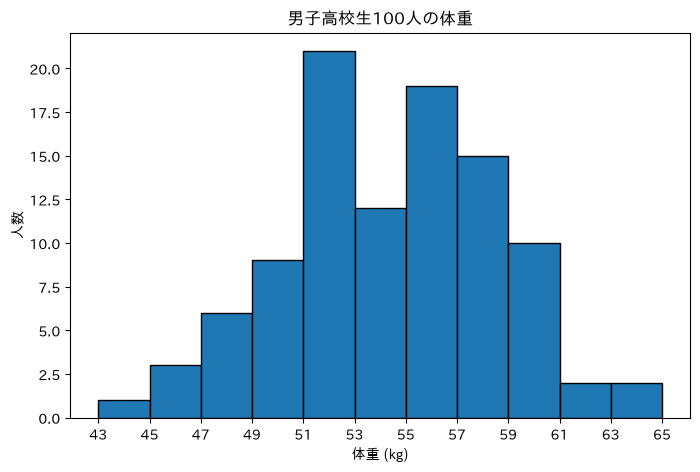

In [7]:
df_weight = pd.read_excel('dsa2026data.xlsx', sheet_name='weight')

plt.figure(figsize=(8, 5))
plt.hist(df_weight['体重'], bins=11, range=(43, 65), edgecolor='k')
plt.xticks(range(43, 66, 2))
plt.title('男子高校生100人の体重')
plt.xlabel('体重 (kg)')
plt.ylabel('人数')
plt.show()

- 棒の高さが [3] の表の人数と同じになっていることを確かめよう（51〜53 kg が 21人でいちばん多い）
- `plt.xticks(range(43, 66, 2))` は、横軸の目盛りを区間の境目（43, 45, …, 65）にする
- matplotlib も、境目ちょうどの値は右側の区間に入れる。だから表1.2 と同じ人数になる

### 演習のひな形

演習「ヒストグラムの描画」では、30人の点数のリスト `score` を使う。区間の決め方を書かないと、matplotlib が**データの最小値から最大値まで**を自動で10等分する。


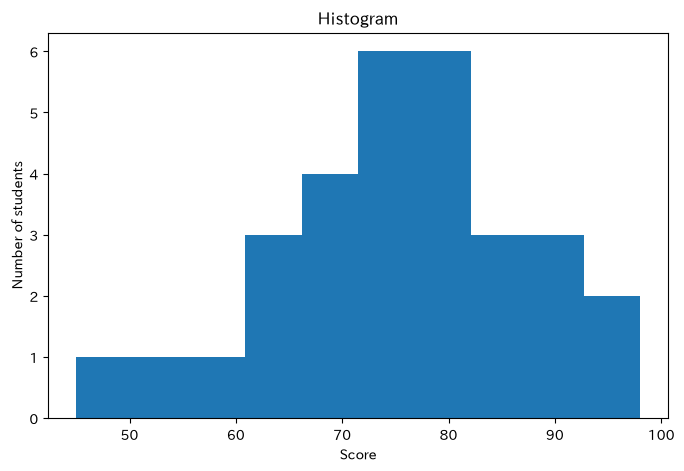

In [8]:
score = [45, 52, 58, 61, 63, 65, 67, 68, 70, 71, 72, 73, 74, 75, 75,
         76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 88, 90, 92, 95, 98]

plt.figure(figsize=(8, 5))
plt.hist(score)
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

- 区切りは 45〜98 点を10等分した半端な値（50.3、55.6 …）になる。0〜100 点を10点刻みにする方法は Q-4
- これが演習「ヒストグラムの描画」のひな形

## Q-2 区切りの数

- `bins=` で**区間の数**を決める（bin＝箱）。何も書かないと `10`
- 少なすぎると形が分からず、多すぎるとガタガタになる。データの数が30くらいなら 5〜10 が目安

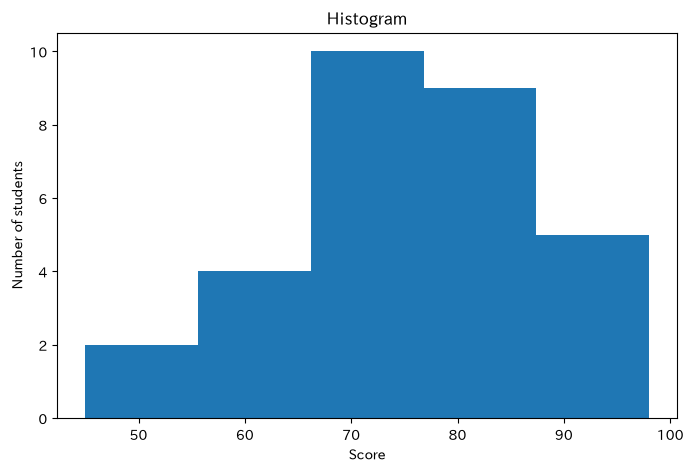

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=5)
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

## Q-3 色と枠線

- 棒グラフと同じく `color=`、`edgecolor=`。ヒストグラムは棒がくっついているので、**枠線を付けると区切りが見やすい**

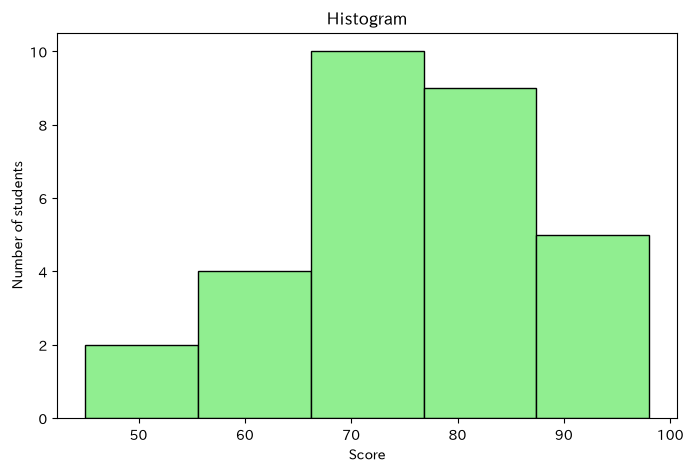

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=5, color='lightgreen', edgecolor='k')
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

- 上の図は、棒の区切りと横軸の数字がずれて見える。2つは別々に決まるため
  - 棒の区切り：データの最小値 45 点から最大値 98 点までを `bins=5` で5等分した **45、55.6、66.2、76.8、87.4、98**（1区間 10.6 点）
  - 横軸の数字：matplotlib が区切りとは関係なく、切りのよい値（50、60、70 …）を自動で並べたもの
- 区切りと数字を揃える方法は、次の Q-4

▶ **演習**：`hist_第７講1`（区切りの数と、色・枠線）

## Q-4 区切りの範囲

- 何も書かないと、区間は**データの最小値から最大値まで**になる（上の図は 45〜98 点）。区切りが 55.6 点のような半端な値になる
- `range=(0, 100)` と書くと 0〜100 点を区切る。`bins=10` と合わせると、**10点刻み**（0〜10, 10〜20, …）になる
- `(0, 100)` のように ( ) で値を組にしたものを**タプル**という。`figsize=(8, 5)` と同じ書き方。`[0, 100]` とリストで書いても動くが、この授業では ( ) で書く

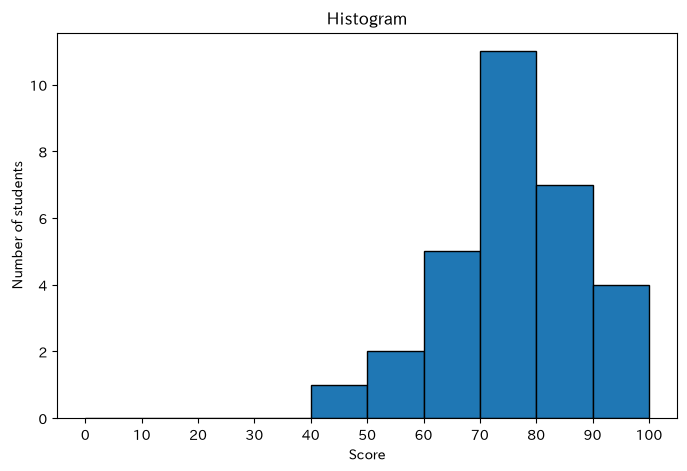

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=10, range=(0, 100), edgecolor='k')
plt.xticks(range(0, 101, 10))
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

- `plt.xticks(range(0, 101, 10))` は、横軸の目盛りを 0, 10, 20, …, 100 にする（なくてもよい）
- 名前は同じ range だが、別のもの。`range=(0, 100)`（= あり）は `plt.hist` の**区切りの範囲**の指定、`range(0, 101, 10)`（= なし）は 0 から 10 おきに数を並べる **Python の命令**（最後の 101 は含まないので、100 まで並ぶ）
- 10点刻みのように切りのよい値にならないときも、考え方は同じ。**1区間の幅 ＝（終わり − 始め）÷ `bins`** を計算して、その幅で目盛りを並べる
- 下の例は 40〜100 点を4つに分ける。幅は (100 − 40) ÷ 4 = **15点**なので、目盛りは `range(40, 101, 15)` で 40, 55, 70, 85, 100
- 幅が 12.5 点のように小数になると `range()` では並べられない（`range()` は整数だけ）。割り切れる `bins` を選ぶとよい

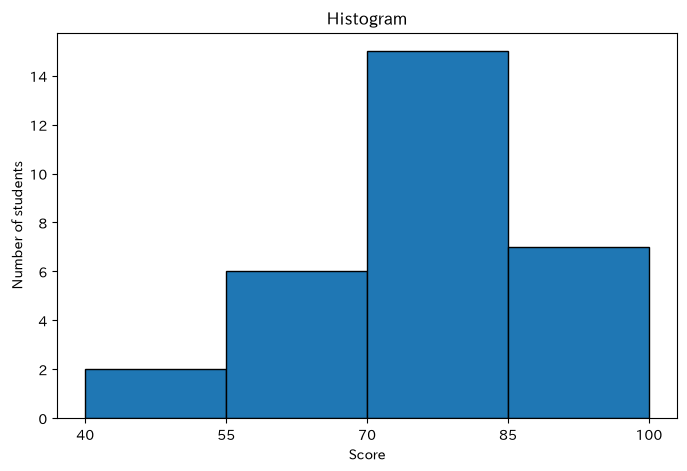

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=4, range=(40, 100), edgecolor='k')  # 40〜100点を4つに分ける → 15点刻み
plt.xticks(range(40, 101, 15))  # 目盛りも15点刻み：40, 55, 70, 85, 100
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

▶ **演習**（発展）：`hist_第７講3`（15点刻みで、目盛りを棒の区切りと揃える）

## Q-5 平均の補助線

- ヒストグラムでは点数が**横軸**にあるので、平均は**縦の線** `plt.axvline(x=np.mean(データ))`（第６講 N-7 の横棒グラフのときと同じ）

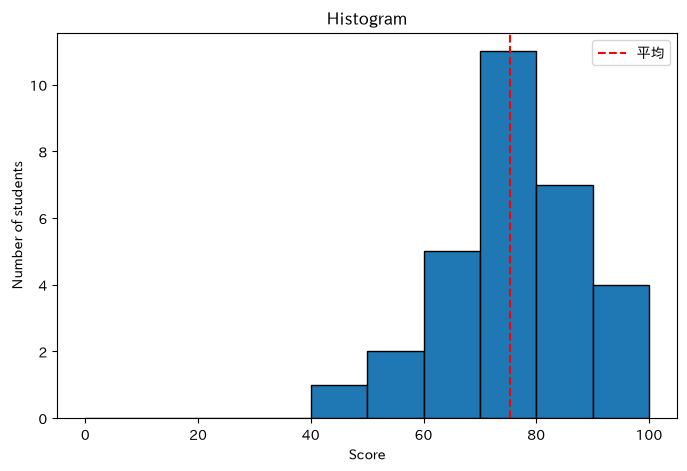

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=10, range=(0, 100), edgecolor='k')
plt.axvline(x=np.mean(score), color='r', linestyle='--', label='平均')
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.legend()
plt.show()

▶ **演習**：`hist_第７講2`（0〜100点の10点刻みと、平均の補助線）

## Q-6 2つのグループを重ねる

- 第４講の散布図と同じく、`plt.hist` を**2回**書くと重なる
- 後ろが隠れないように `alpha=0.5`（透明度）、どちらがどちらか分かるように `label=` と `plt.legend()`
- 2つの `bins=` と `range=` は**同じ値**にする（区間がずれると比べられない）

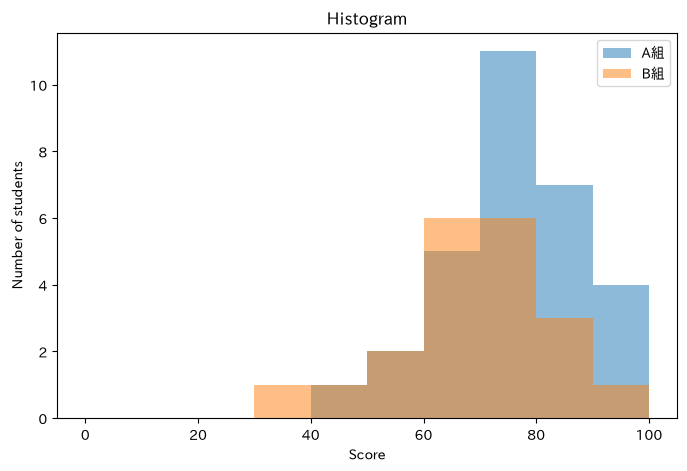

In [13]:
score_b = [38, 47, 55, 58, 60, 62, 64, 66, 67, 69,
           70, 71, 72, 74, 76, 78, 80, 83, 87, 91]

plt.figure(figsize=(8, 5))
plt.hist(score, bins=10, range=(0, 100), alpha=0.5, label='A組')
plt.hist(score_b, bins=10, range=(0, 100), alpha=0.5, label='B組')
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.legend()
plt.show()

▶ **演習**：`hist_描画基礎005`（A組とB組を重ねる）

## Q-7 Excel のデータでヒストグラム

- `exam` シートは30人の5教科の点数（名前は架空）。`df_exam['数学']` で数学の点数を取り出して描く

In [14]:
df_exam = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
df_exam.head()

,name,国語,数学,理科,社会,英語
0,伊藤 涼介,94,76,62,81,62
1,上田 美咲,63,57,59,80,74
2,木村 太郎,55,66,82,78,66
3,佐藤 亜美,61,87,80,65,78
4,鈴木 恵美子,56,58,69,97,61


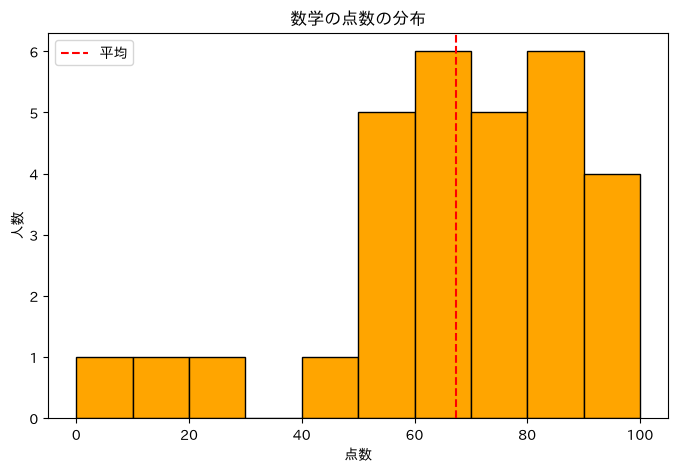

In [15]:
plt.figure(figsize=(8, 5))
plt.hist(df_exam['数学'], bins=10, range=(0, 100), color='orange', edgecolor='k')
plt.axvline(x=np.mean(df_exam['数学']), color='r', linestyle='--', label='平均')
plt.title('数学の点数の分布')
plt.xlabel('点数')
plt.ylabel('人数')
plt.legend()
plt.show()

### 使ってみよう
- `'数学'` を `'社会'` に変えてみよう（2か所）。平均は近いのに、分布の形はかなり違う
- `'数学'` と `'英語'` を Q-6 のように重ねてみよう

In [16]:
# ここで試してみよう

---
# R. 箱ひげ図

**箱ひげ図**は、いくつかのグループの**ばらつき**を並べて比べるグラフ。ヒストグラムを横から見て、5つの数にまとめたもの。

演習「第７講」の箱ひげ図の問題（box）のひな形は R-2 にある。

## R-0 今日の完成形

今日はこのグラフを目指す（30人の5教科の点数のばらつき）。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する（`Shift + Enter`）
1. まずは**数値や文字を変えて**、グラフのどこが変わるかを確かめる
1. そのあと、箱ひげ図の読み方（R-1）を確かめてから、各部品（[0]〜[7]）の働きを学ぶ（R-2〜R-7）

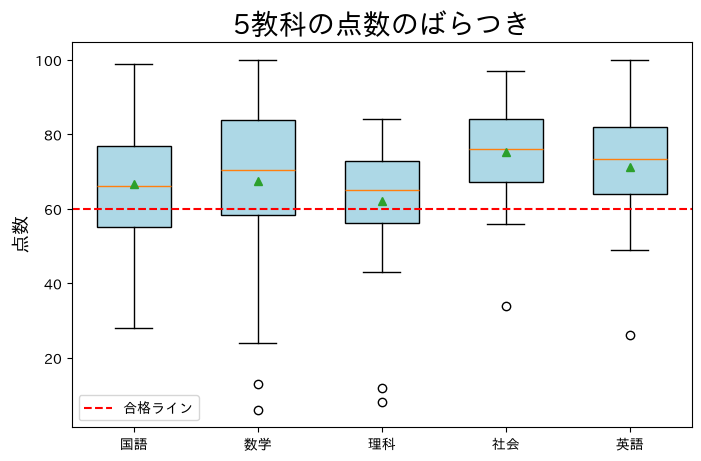

In [17]:
df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')  # Excel を読む

plt.figure(figsize=(8, 5))  # [0] グラフの大きさ
plt.boxplot([df['国語'], df['数学'], df['理科'], df['社会'], df['英語']],  # [1] 箱ひげ図 [6] Excel の列を並べる
            widths=0.6, patch_artist=True, boxprops={'facecolor': 'lightblue'},  # [3] 箱の幅と塗りつぶし
            showmeans=True)  # [4] 平均
plt.xticks([1, 2, 3, 4, 5], ['国語', '数学', '理科', '社会', '英語'])  # [2] 項目の名前
plt.axhline(y=60, color='r', linestyle='--', label='合格ライン')  # [5] 補助線
plt.title('5教科の点数のばらつき', fontsize=20)  # [7] タイトル
plt.ylabel('点数', fontsize=14)  # [7] 縦軸の名前
plt.legend()  # [7] 凡例
plt.show()

- `plt.boxplot(...)` は1つの命令。長いので `,` の後ろで**改行**している（`(` の中なら、次の行も続きとして読まれる。第６講 O-0）

### 変えてみよう（1か所変えたら、もう一度実行する）

- 色：`'lightblue'` → `'pink'`、`'lightgreen'`
- 幅：`widths=0.6` → `widths=0.3`、`widths=1`
- `showmeans=True` を `showmeans=False` にすると、何が消えるか
- 合格ライン：`y=60` → `y=70`
- `plt.xticks(...)` の行頭に `#` を付けると、横軸の下がどうなるか

In [18]:
# 上のコードを貼り付けて、値を変えてみよう

| 番号 | 部品 | 書き方 | 学ぶところ | 演習「第７講」 |
|---|---|---|---|---|
| [0] | グラフの大きさ（基本設定） | `plt.figure(figsize=(8, 5))` | 第３講 | （どの問題でも書いてよい） |
| [1] | 箱ひげ図を描く | `plt.boxplot([データ1, データ2, …])` | R-2 | （ひな形） |
| [2] | 項目の名前 | `plt.xticks([1, 2, 3], ['名前1', '名前2', '名前3'])` | R-3 | `box_第７講1`、`box_第７講2` |
| [3] | 箱の幅と塗りつぶし | `widths=0.6`、`patch_artist=True, boxprops={'facecolor': '色'}` | R-4 | `box_第７講1` |
| [4] | 平均を表示する | `showmeans=True` | R-5 | `box_第７講2` |
| [5] | 補助線 | `plt.axhline(y=60, label='合格ライン')` | R-6 | `box_第７講2` |
| [6] | Excel の列を並べる | `[df['国語'], df['数学'], …]` | R-7 | （演習なし） |
| [7] | タイトル・軸の名前・凡例 | `plt.title`、`plt.legend()` など | 第３講 | （書いてもよい。`box_第７講2` では凡例が必要） |
| | 箱ごとに色を変える | `bp['boxes']` と for 文 | T-2（発展） | `box_描画基礎005` |

- 演習では、**問題で指定されたものだけ**書く（完成形をそのまま貼らない）

## R-1 箱ひげ図の読み方

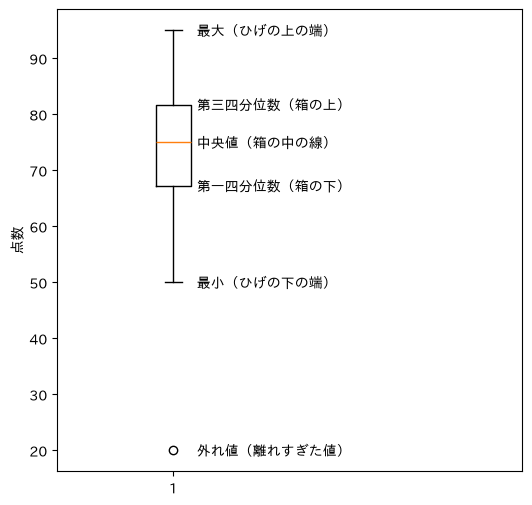

In [19]:
data = [50, 52, 58, 61, 63, 65, 67, 68, 70, 71, 72, 73, 74, 75, 75,
        76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 88, 90, 92, 95, 20]

plt.figure(figsize=(6, 6))
plt.boxplot(data)
plt.text(1.1, np.max(data[:-1]), '最大（ひげの上の端）', va='center')
plt.text(1.1, np.percentile(data, 75), '第三四分位数（箱の上）', va='center')
plt.text(1.1, np.median(data), '中央値（箱の中の線）', va='center')
plt.text(1.1, np.percentile(data, 25), '第一四分位数（箱の下）', va='center')
plt.text(1.1, np.min(data[:-1]), '最小（ひげの下の端）', va='center')
plt.text(1.1, 20, '外れ値（離れすぎた値）', va='center')
plt.xlim(0.5, 2.5)
plt.ylabel('点数')
plt.show()

| 部分 | 意味 |
|---|---|
| 箱の中の線 | **中央値**（大きさの順に並べて真ん中の値） |
| 箱 | 第一四分位数から第三四分位数まで（四分位範囲、第４講 G-2）。真ん中の半分（50%）の人が入る範囲。箱が**長いほどばらつきが大きい** |
| ひげ | 外れ値を除いた最小から最大まで |
| ○ | **外れ値**（ほかから離れすぎた値）。箱の長さの 1.5 倍より外にある値 |

- 上の図の文字は `plt.text`（第４講 H-10 で使った。くわしくは第８講）で書いている。今は読み方だけ分かればよい

## R-2 箱ひげ図の基本

- `plt.boxplot([データ1, データ2, …])` で、グループごとの箱が**左から順に**並ぶ
- データは**リストのリスト**（`[ ]` の中にリストを並べる）で渡す
- 演習「第７講」の箱ひげ図の問題（box）のひな形は次の形

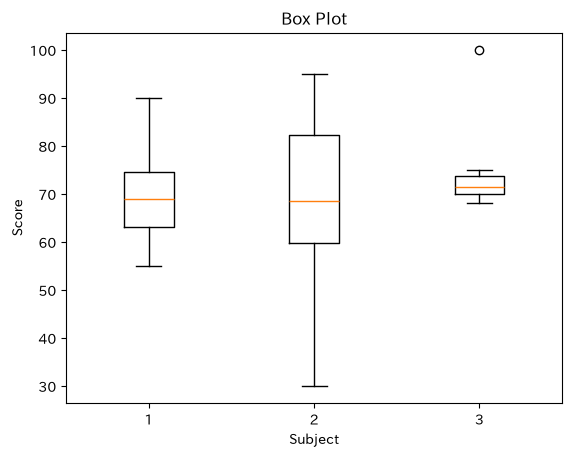

In [20]:
japanese = [62, 75, 58, 81, 70, 66, 90, 55, 73, 68]
math = [45, 88, 62, 95, 30, 71, 84, 59, 77, 66]
english = [70, 72, 68, 75, 74, 69, 71, 73, 100, 70]

plt.boxplot([japanese, math, english])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

- 数学（2番目）は箱が長い＝点数がばらばら。英語（3番目）は箱が短い＝みんな同じくらい。英語の 100 点は外れ値（○）
- 箱が1つだけなら `plt.boxplot(japanese)` でもよい

## R-3 項目の名前

- 横軸の下には `1, 2, 3` と番号が付く。`plt.xticks([1, 2, 3], ['名前1', '名前2', '名前3'])` で名前に置き換える
- 番号と名前は**同じ個数**にする

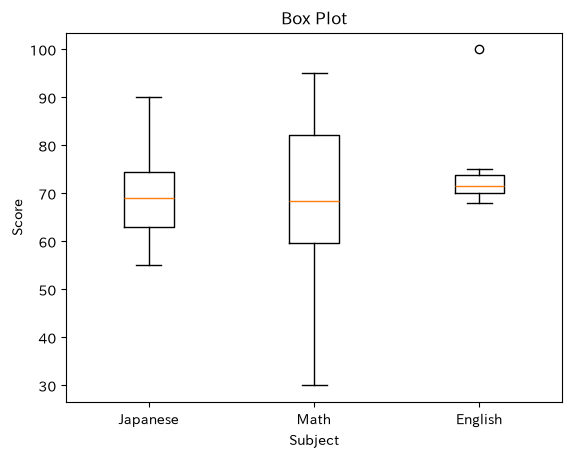

In [21]:
plt.boxplot([japanese, math, english])
plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

- `plt.boxplot(..., tick_labels=['Japanese', 'Math', 'English'])` と書いても同じ（matplotlib 3.9 より古いと `labels=`）。どの環境でも動くので、この授業では `plt.xticks` を使う

## R-4 箱の幅と塗りつぶし

- `widths=0.6` で箱の幅を変える（何も書かないと、箱の数に合わせて 0.15〜0.5 の間で決まる。`1` で隣の箱とくっつく）
- `patch_artist=True` で箱の中を**塗りつぶす**（何も書かないと白抜き）。塗る色は `boxprops={'facecolor': '色'}`

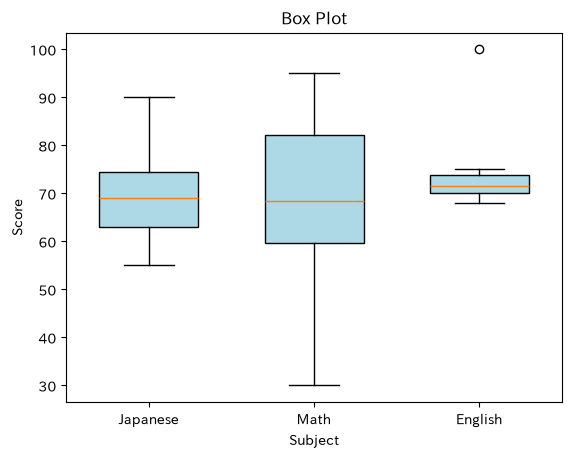

In [22]:
plt.boxplot([japanese, math, english], widths=0.6, patch_artist=True, boxprops={'facecolor': 'lightblue'})
plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

- `{'facecolor': 'lightblue'}` は**辞書**という書き方（`{'名前': 値}`）。ここでは「箱の中の色は lightblue」と読めばよい

▶ **演習**：`box_第７講1`（項目の名前と、箱の幅・塗りつぶし）

## R-5 平均を表示する

- 箱の中の線は**中央値**で、平均ではない。`showmeans=True` で**平均**を ▲ で表示する
- 外れ値があると、平均は中央値から外れ値の側へずれる

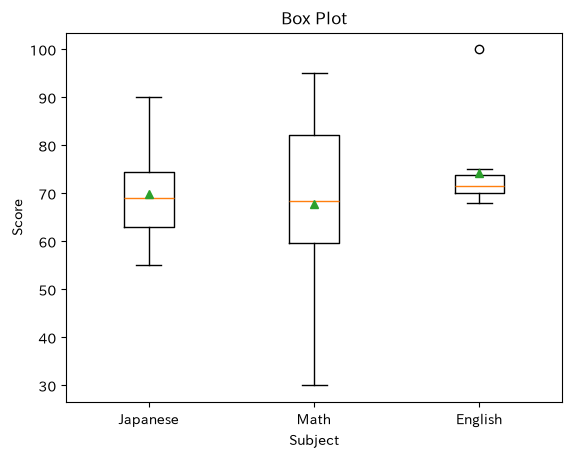

In [23]:
plt.boxplot([japanese, math, english], showmeans=True)
plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

## R-6 補助線を引く

- 第４講の `plt.axhline(y=値)` が箱ひげ図でも使える。合格ラインや全体の平均を引く

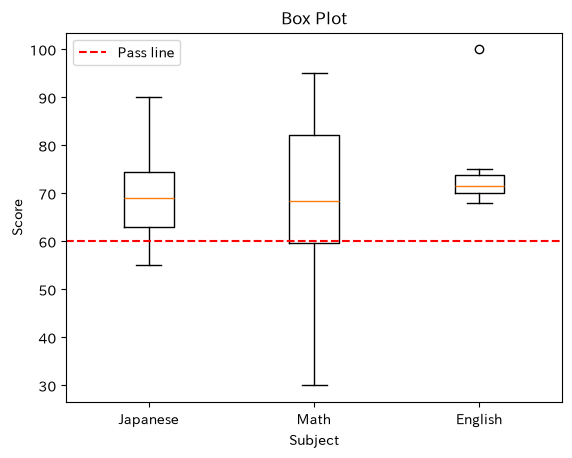

In [24]:
plt.boxplot([japanese, math, english])
plt.axhline(y=60, color='r', linestyle='--', label='Pass line')
plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.legend()
plt.show()

▶ **演習**：`box_第７講2`（平均の表示と、合格ラインの補助線）

## R-7 Excel のデータで箱ひげ図

- `exam` シートの5教科を並べる。`df['国語']` などを**リストの中に**並べて渡す

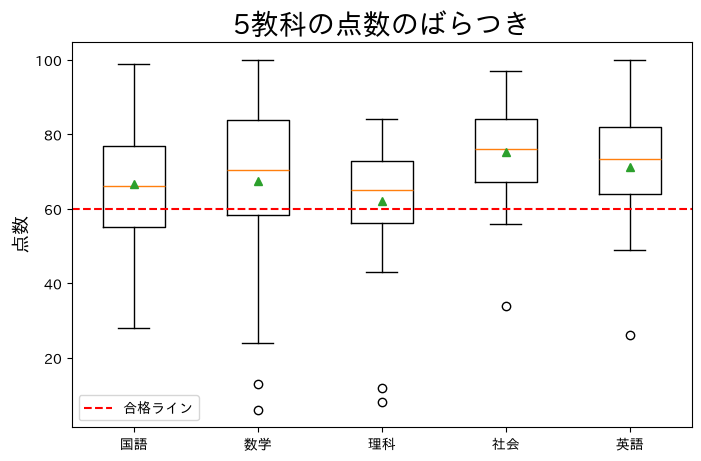

In [25]:
plt.figure(figsize=(8, 5))
plt.boxplot([df['国語'], df['数学'], df['理科'], df['社会'], df['英語']], showmeans=True)
plt.xticks([1, 2, 3, 4, 5], ['国語', '数学', '理科', '社会', '英語'])
plt.axhline(y=60, color='r', linestyle='--', label='合格ライン')
plt.title('5教科の点数のばらつき', fontsize=20)
plt.ylabel('点数', fontsize=14)
plt.legend()
plt.show()

### 使ってみよう
- 社会は箱が短く、数学は長い。点数のばらつきが大きいのはどの教科か
- 理科の下にある ○ は誰の点数か、`df` の表で探してみよう
- Q-0 の数学のヒストグラムと見比べてみよう（箱が長い＝ヒストグラムの山が横に広い）

In [26]:
# ここで試してみよう

---
# S. リストの操作

第４講の散布図では、点の大きさや色を**リスト**で渡した（第４講 H-3・H-4）。点が多くなると、リストを手で書くのは大変になる。ここではリストを**短く作る・数える・書き換える**方法を学ぶ。

## S-1 リストの作成と参照（復習）

- `[ ]` の中に `,` で区切って値を並べる
- 値を取り出すときは `リスト名[番号]`。**番号は 0 から**

In [27]:
a = [1, 2, 3, 4]

print(a[0])
print(a[2])

1
3


▶ **演習**：`リストの作成と参照基礎001`

## S-2 同じものを並べる・個数を数える

- `リスト * 個数` で、同じ要素を並べたリストが作れる

In [28]:
ini_list = ['y']
colorlist = ini_list * 5

print(colorlist)

['y', 'y', 'y', 'y', 'y']


- `len(リスト)` で、リストの**要素の個数**が分かる（第２講）
- `len` と組み合わせると、**別のリストと同じ個数**のリストが作れる。数字を直接書かない（**ベタ打ち・ハードコード**しない）ので、data の個数が変わっても直さなくてよい

In [29]:
data = [7, 1, 3, 6, 4, 6, 1, 8, 0, 2, 1, 0, 5, 3, 1, 3, 6, 3, 4, 0]

mylist = ['y'] * len(data)

print(len(data))
print(mylist)

20
['y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y']


▶ **演習**：`リストの作成と参照基礎002`、`リストの作成と参照基礎003`

### 使ってみよう：第４講 H-4 の色のリストを短く書く

- 第４講 H-4 では `['m', 'm', 'm', 'b', 'b', 'b']` と手で書いた
- リストどうしは `+` でつなげられる

['m', 'm', 'm', 'b', 'b', 'b']


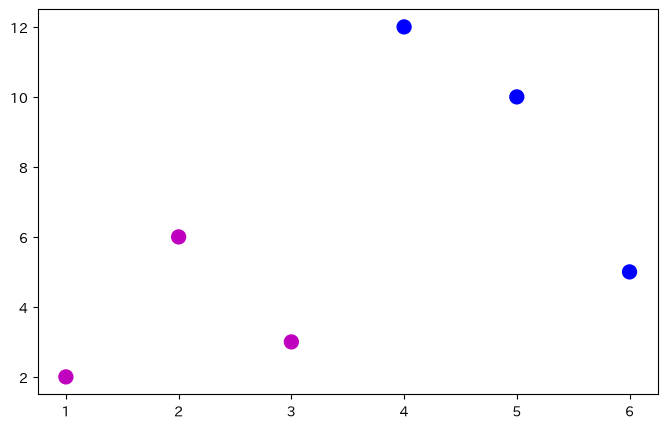

In [30]:
x = [1, 2, 3, 4, 5, 6]
y = [2, 6, 3, 12, 10, 5]

mycolors = ['m'] * 3 + ['b'] * 3
print(mycolors)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, marker='o', s=100, color=mycolors)
plt.show()

## S-3 要素を書き換える

- `リスト名[番号] = 新しい値` で、その番号の要素だけを書き換える

In [31]:
mylist = ['y'] * len(data)
mylist[0] = 'r'

print(mylist)

['r', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y', 'y']


- 先頭は `[0]`、最後は `[-1]` と書ける

▶ **演習**：`リストの作成と参照基礎004`

- 演習「第７講（リスト）」の 006〜010 は **numpy の配列（np.array）**を使う**発展編**の問題（第４講 I-1）。できる人だけ挑戦する（解かなくても課題には困らない）

---
# T. 発展（できる人だけ）

ここは授業の本編ではない。課題に使わなくても困らない。

## T-1 ヒストグラムを並べる・横向きにする

- `plt.hist([データ1, データ2])` のように**リストにまとめて**渡すと、重ねずに**横に並べて**描く。`label=` もリストで渡す

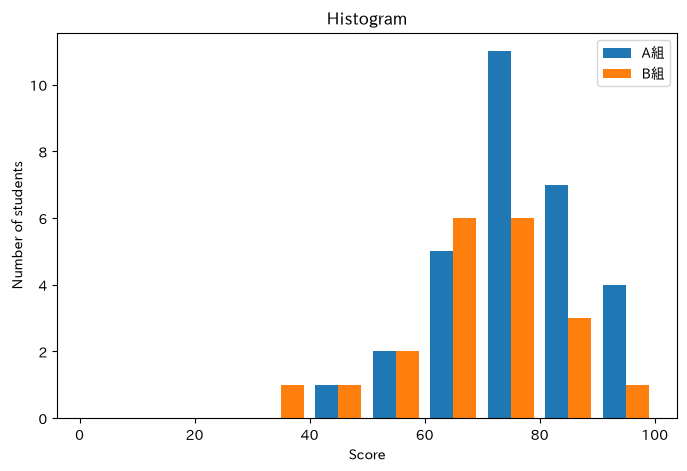

In [32]:
plt.figure(figsize=(8, 5))
plt.hist([score, score_b], bins=10, range=(0, 100), label=['A組', 'B組'])
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.legend()
plt.show()

▶ **演習**（発展）：`hist_描画基礎006`

- `orientation='horizontal'` で横向きになる。横棒グラフ（第６講 N-7）と同じく `xlabel` と `ylabel` を入れ替え、平均の線は**横の線** `plt.axhline`

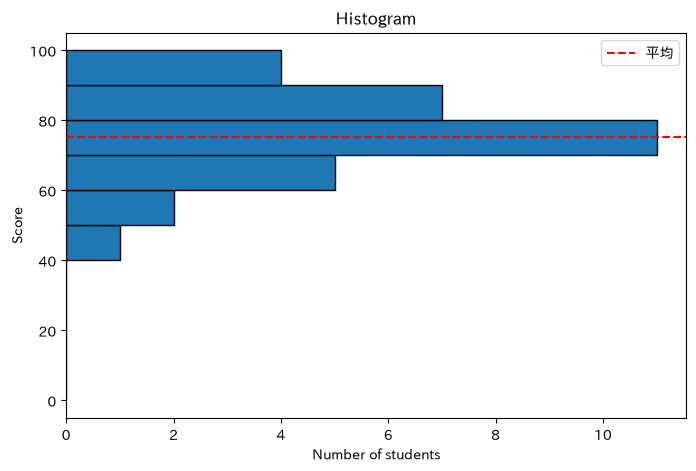

In [33]:
plt.figure(figsize=(8, 5))
plt.hist(score, bins=10, range=(0, 100), edgecolor='k', orientation='horizontal')
plt.axhline(y=np.mean(score), color='r', linestyle='--', label='平均')
plt.title('Histogram')
plt.xlabel('Number of students')
plt.ylabel('Score')
plt.legend()
plt.show()

▶ 横向きの問題は、演習「ヒストグラムの描画」の `hist_描画基礎007`（発展）

## T-2 箱ごとに色を変える

- `patch_artist=True` を付けて描いた結果を変数（ここでは `bp`）に入れると、`bp['boxes']` で箱を1つずつ取り出せる
- for 文（第８講）で、箱ごとに色を塗る

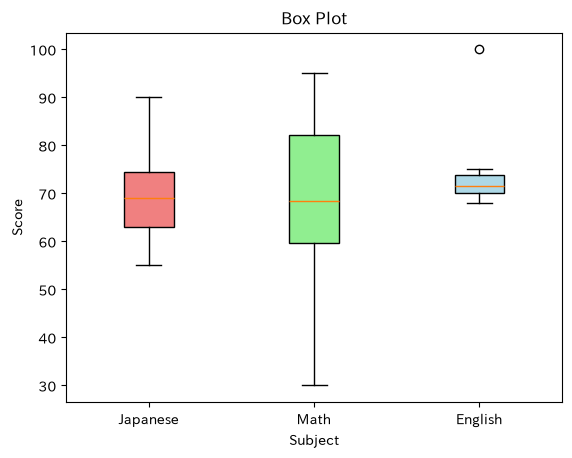

In [34]:
bp = plt.boxplot([japanese, math, english], patch_artist=True)
mycolor = ['lightcoral', 'lightgreen', 'lightblue']
for box, c in zip(bp['boxes'], mycolor):
    box.set_facecolor(c)

plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

▶ **演習**（発展）：`box_描画基礎005`

## T-3 ヒストグラムの1本だけ色を変える

- 棒グラフ（第６講 P-4）では `color=` に色のリストを渡せたが、`plt.hist` の `color=` は**全部の棒に同じ色**しか付けられない
- そこで、描いた棒をあとから1本取り出して色を塗り替える（T-2 の箱と同じ考え方）
- `plt.hist` は描いた結果を**3つ**返す。`n, bins, patches = plt.hist(...)` のように、`,` で区切った3つの変数で受け取る
  - `n`：各区間の人数
  - `bins`：区切りの位置
  - `patches`：棒（左から順に入っている）
- `patches` はリストと同じく先頭が `[0]`（S-1）。10点刻みなら 0〜10点が `[0]`、10〜20点が `[1]` … 70〜80点が `[7]`
- `patches[7].set_facecolor('r')` で、その棒だけ色が変わる（`facecolor` は塗りの色。枠線の色は `edgecolor`）

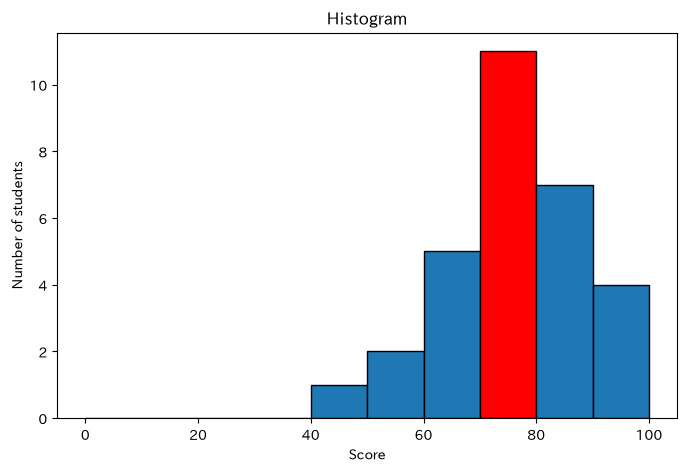

In [ ]:
plt.figure(figsize=(8, 5))
n, bins, patches = plt.hist(score, bins=10, range=(0, 100), edgecolor='k')
patches[7].set_facecolor('r')  # 左から8本目（70〜80点）だけ赤
plt.title('Histogram')
plt.xlabel('Score')
plt.ylabel('Number of students')
plt.show()

▶ **演習**（発展）：`hist_第７講4`（人数が最も多い区間の棒だけ赤にする）

---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| **以下は復習** | |
| 文字の値を数える | `count = df['列名'].value_counts()` → `count.index`（名前）、`count.values`（件数） |
| **以下はヒストグラム** | |
| ヒストグラム | `plt.hist(データ)` |
| 区間の数・範囲 | `bins=10`、`range=(0, 100)` |
| 色・枠線 | `color='lightgreen'`、`edgecolor='k'` |
| 平均の補助線 | `plt.axvline(x=np.mean(データ))` |
| 2つのグループを重ねる | `plt.hist` を2回、`alpha=0.5`、`label=` と `plt.legend()` |
| **以下は箱ひげ図** | |
| 箱ひげ図 | `plt.boxplot([データ1, データ2, …])` |
| 項目の名前 | `plt.xticks([1, 2, 3], ['名前1', '名前2', '名前3'])` |
| 箱の幅・塗りつぶし | `widths=0.6`、`patch_artist=True, boxprops={'facecolor': '色'}` |
| 平均を表示 | `showmeans=True` |
| 補助線 | `plt.axhline(y=60)` |
| **以下はリスト** | |
| 同じものを並べる | `['y'] * 5`、`['y'] * len(data)` |
| 個数を数える | `len(リスト)` |
| 書き換える | `リスト[番号] = 新しい値`（最後は `[-1]`） |

次回（第８講）は **for 文**（同じ処理のくり返し）と、グラフに文字を書く**注釈**（`plt.text`）。